# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Muhammad Al - Fatih
- NIM   : 241011401716
- Kelas : Reg B

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 16

In [8]:
def train_test_split(X, y, test_size=0.2, random_state=None):
    if random_state is not None:
        np.random.seed(random_state)

    n_samples = len(X)
    n_test = int(n_samples * test_size)

    indices = np.random.permutation(n_samples)
    test_idx = indices[:n_test]
    train_idx = indices[n_test:]

    if isinstance(X, pd.DataFrame):
        X_train, X_test = X.iloc[train_idx].values, X.iloc[test_idx].values
    else:
        X_train, X_test = X[train_idx], X[test_idx]

    if isinstance(y, pd.Series):
        y_train, y_test = y.iloc[train_idx].values, y.iloc[test_idx].values
    else:
        y_train, y_test = y[train_idx], y[test_idx]

    return X_train, X_test, y_train, y_test

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

5 Data Pertama:
   BiayaIklan  Penjualan
0         0.8       34.3
1         0.9       38.8
2         1.0       33.2
3         1.3       36.0
4         1.7       51.3

Jumlah baris data: 40


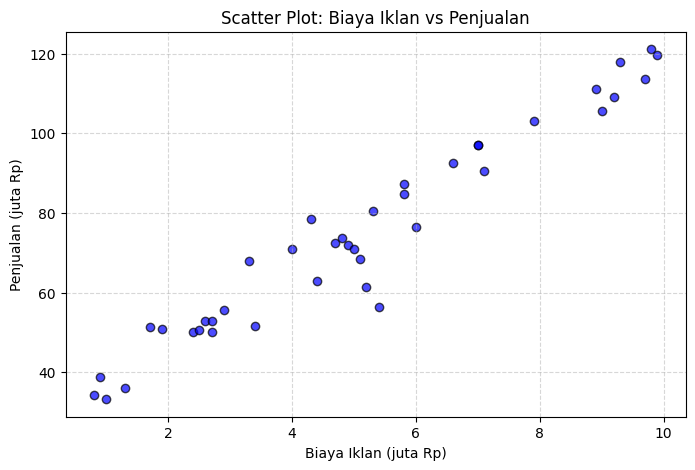

In [9]:
# Jawaban A1
df_ads = pd.read_csv('Ads_Data.csv')
print("5 Data Pertama:")
print(df_ads.head())
print(f"\nJumlah baris data: {df_ads.shape[0]}")

X_ads = df_ads[['BiayaIklan']].values
y_ads = df_ads['Penjualan'].values

plt.figure(figsize=(8, 5))
plt.scatter(df_ads['BiayaIklan'], df_ads['Penjualan'], color='blue', alpha=0.7, edgecolors='k')
plt.title('Scatter Plot: Biaya Iklan vs Penjualan')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [10]:
# Jawaban A2
X_train_a, X_test_a, y_train_a, y_test_a = train_test_split(X_ads, y_ads, test_size=0.2, random_state=RANDOM_STATE)

print(f"Shape X_train: {X_train_a.shape}")
print(f"Shape X_test : {X_test_a.shape}")
print(f"Shape y_train: {y_train_a.shape}")
print(f"Shape y_test : {y_test_a.shape}")

Shape X_train: (32, 1)
Shape X_test : (8, 1)
Shape y_train: (32,)
Shape y_test : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [11]:
# Jawaban A3
X_train_b = np.c_[np.ones(X_train_a.shape[0]), X_train_a]

theta = np.linalg.inv(X_train_b.T.dot(X_train_b)).dot(X_train_b.T).dot(y_train_a)

b = theta[0]
m = theta[1]

print(f"Intercept (b)  = {b:.4f}")
print(f"Koefisien (m)  = {m:.4f}")
print(f"Persamaan Garis: y_hat = {b:.4f} + {m:.4f} * X")

Intercept (b)  = 28.8540
Koefisien (m)  = 9.0063
Persamaan Garis: y_hat = 28.8540 + 9.0063 * X


**Jawaban A3 (interpretasi):**

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [12]:
# Jawaban A4
def evaluate_regression(y_true, y_pred):
    mae = np.mean(np.abs(y_true - y_pred))
    mse = np.mean((y_true - y_pred) ** 2)
    rmse = np.sqrt(mse)
    ss_total = np.sum((y_true - np.mean(y_true)) ** 2)
    ss_res = np.sum((y_true - y_pred) ** 2)
    r2 = 1 - (ss_res / ss_total)
    return {'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R2': r2}

y_train_pred = X_train_b.dot(theta)
X_test_b = np.c_[np.ones(X_test_a.shape[0]), X_test_a]
y_test_pred = X_test_b.dot(theta)

train_metrics = evaluate_regression(y_train_a, y_train_pred)
test_metrics = evaluate_regression(y_test_a, y_test_pred)

df_eval = pd.DataFrame([train_metrics, test_metrics], index=['Training', 'Testing'])
print(df_eval)

               MAE        MSE      RMSE        R2
Training  4.494281  33.647050  5.800608  0.946616
Testing   4.700853  46.026552  6.784287  0.916123


**Jawaban A4 (analisis):**

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

LR: 0.001 -> Intercept: 25.3355, Koefisien: 9.5358
LR: 0.02 -> Intercept: 28.8540, Koefisien: 9.0063


/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:136: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
/tmp/ipykernel_1132/3120755466.py:16: RuntimeWarning: overflow encountered in square
  mse = np.mean((y_pred - y) ** 2)
/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:86: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
/tmp/ipykernel_1132/3120755466.py:23: RuntimeWarning: invalid value encountered in scalar subtract
  self.m -= self.lr * dm
/usr/local/lib/python3.13/dist-packages/matplotlib/scale.py:253: RuntimeWarning: overflow encountered in power
  return np.power(self.base, values)


LR: 0.1 -> Intercept: nan, Koefisien: nan


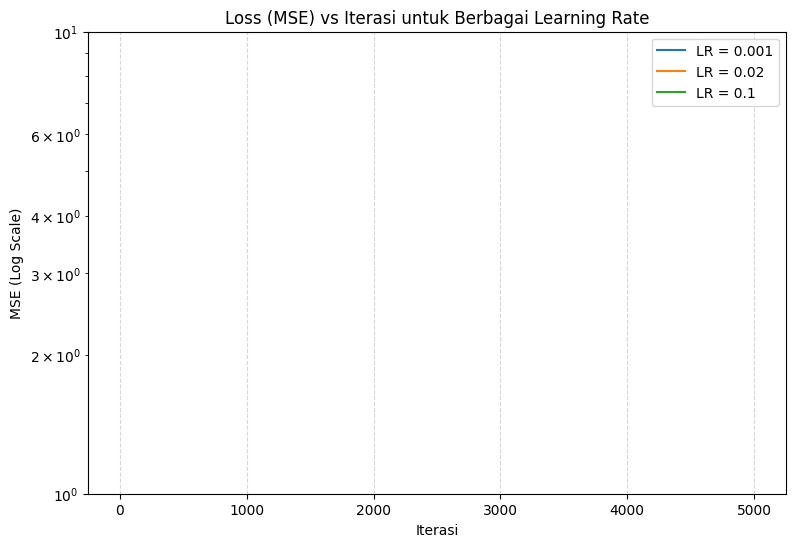

In [22]:
# Jawaban A5
class LinearRegressionGD:
    def __init__(self, learning_rate=0.01, n_iterations=5000):
        self.lr = learning_rate
        self.n_iters = n_iterations
        self.b = 0.0
        self.m = 0.0
        self.history = []

    def fit(self, X, y):
        n = len(X)
        self.b = 0.0
        self.m = 0.0
        for i in range(self.n_iters):
            y_pred = self.b + self.m * X.ravel()
            mse = np.mean((y_pred - y) ** 2)
            self.history.append(mse)

            db = (2/n) * np.sum(y_pred - y)
            dm = (2/n) * np.sum((y_pred - y) * X.ravel())

            self.b -= self.lr * db
            self.m -= self.lr * dm
        return self

learning_rates = [0.001, 0.02, 0.1]
models_gd = {}

plt.figure(figsize=(9, 6))
for lr in learning_rates:
    gd = LinearRegressionGD(learning_rate=lr, n_iterations=5000)
    gd.fit(X_train_a, y_train_a)
    models_gd[lr] = gd
    print(f"LR: {lr} -> Intercept: {gd.b:.4f}, Koefisien: {gd.m:.4f}")
    plt.plot(gd.history, label=f'LR = {lr}')

plt.yscale('log')
plt.title('Loss (MSE) vs Iterasi untuk Berbagai Learning Rate')
plt.xlabel('Iterasi')
plt.ylabel('MSE (Log Scale)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

**Jawaban A5 (analisis):**

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

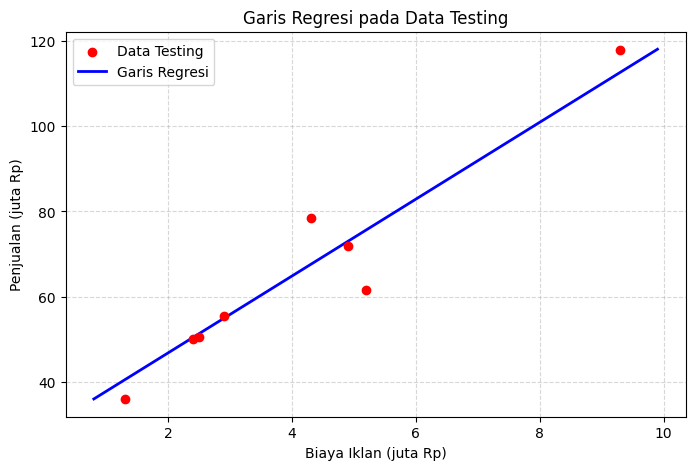

Biaya Iklan 4.5 juta -> Prediksi Penjualan: 69.3825 juta
Biaya Iklan 7.0 juta -> Prediksi Penjualan: 91.8983 juta
Biaya Iklan 12.0 juta -> Prediksi Penjualan: 136.9299 juta


In [14]:
# Jawaban A6
plt.figure(figsize=(8, 5))
plt.scatter(X_test_a, y_test_a, color='red', label='Data Testing', zorder=5)
X_line = np.linspace(X_ads.min(), X_ads.max(), 100)
y_line = b + m * X_line
plt.plot(X_line, y_line, color='blue', label='Garis Regresi', linewidth=2)
plt.title('Garis Regresi pada Data Testing')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

biaya_baru = np.array([4.5, 7.0, 12.0])
prediksi = b + m * biaya_baru
for b_val, p_val in zip(biaya_baru, prediksi):
    print(f"Biaya Iklan {b_val} juta -> Prediksi Penjualan: {p_val:.4f} juta")

**Jawaban A6 (analisis):**

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

5 Data Pertama:
   JumlahLink  KataPromo  Spam
0           0          0     0
1           2          4     0
2           6          7     1
3          10          8     1
4           8          7     1

Jumlah Bukan Spam (0): 35
Jumlah Spam (1): 25


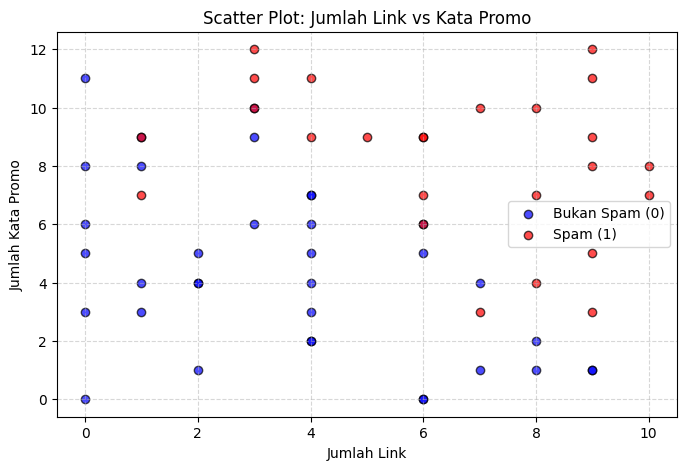

In [15]:
# Jawaban B1
df_email = pd.read_csv('Email_Data.csv')
print("5 Data Pertama:")
print(df_email.head())

spam_counts = df_email['Spam'].value_counts()
print(f"\nJumlah Bukan Spam (0): {spam_counts.get(0, 0)}")
print(f"Jumlah Spam (1): {spam_counts.get(1, 0)}")

plt.figure(figsize=(8, 5))
plt.scatter(df_email[df_email['Spam'] == 0]['JumlahLink'],
            df_email[df_email['Spam'] == 0]['KataPromo'],
            color='blue', label='Bukan Spam (0)', alpha=0.7, edgecolors='k')
plt.scatter(df_email[df_email['Spam'] == 1]['JumlahLink'],
            df_email[df_email['Spam'] == 1]['KataPromo'],
            color='red', label='Spam (1)', alpha=0.7, edgecolors='k')
plt.title('Scatter Plot: Jumlah Link vs Kata Promo')
plt.xlabel('Jumlah Link')
plt.ylabel('Jumlah Kata Promo')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Intercept (b) = -10.2067
Koefisien (m1, m2) = [0.93544249 0.80150125]
Persamaan: P(Spam) = sigma(-10.2067 + 0.9354*Link + 0.8015*KataPromo)


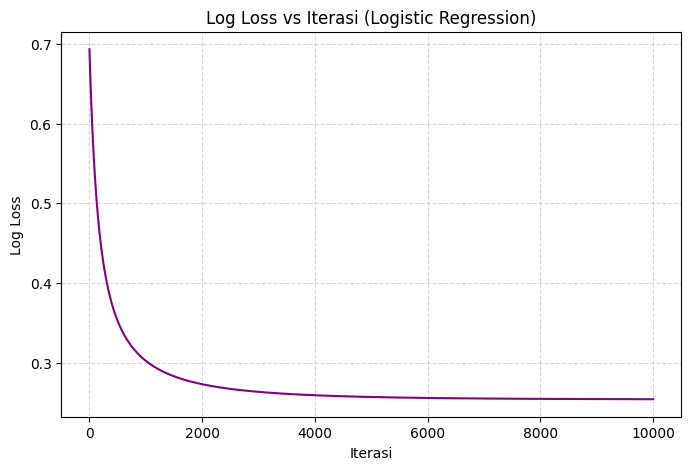

In [16]:
# Jawaban B2
X_email = df_email[['JumlahLink', 'KataPromo']].values
y_email = df_email['Spam'].values

X_train_e, X_test_e, y_train_e, y_test_e = train_test_split(X_email, y_email, test_size=0.25, random_state=RANDOM_STATE)

class LogisticRegressionGD:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.lr = learning_rate
        self.n_iters = n_iterations
        self.b = 0.0
        self.weights = None
        self.loss_history = []

    def sigmoid(self, z):
        return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.weights = np.zeros(n_features)
        self.b = 0.0

        for i in range(self.n_iters):
            linear_model = np.dot(X, self.weights) + self.b
            y_pred = self.sigmoid(linear_model)

            eps = 1e-15
            y_pred_clipped = np.clip(y_pred, eps, 1 - eps)
            loss = -np.mean(y * np.log(y_pred_clipped) + (1 - y) * np.log(1 - y_pred_clipped))
            self.loss_history.append(loss)

            dw = (1 / n_samples) * np.dot(X.T, (y_pred - y))
            db = (1 / n_samples) * np.sum(y_pred - y)

            self.weights -= self.lr * dw
            self.b -= self.lr * db
        return self

    def predict_proba(self, X):
        linear_model = np.dot(X, self.weights) + self.b
        return self.sigmoid(linear_model)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

log_reg = LogisticRegressionGD(learning_rate=0.1, n_iterations=10000)
log_reg.fit(X_train_e, y_train_e)

print(f"Intercept (b) = {log_reg.b:.4f}")
print(f"Koefisien (m1, m2) = {log_reg.weights}")
print(f"Persamaan: P(Spam) = sigma({log_reg.b:.4f} + {log_reg.weights[0]:.4f}*Link + {log_reg.weights[1]:.4f}*KataPromo)")

plt.figure(figsize=(8, 5))
plt.plot(log_reg.loss_history, color='purple')
plt.title('Log Loss vs Iterasi (Logistic Regression)')
plt.xlabel('Iterasi')
plt.ylabel('Log Loss')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

**Jawaban B2 (analisis):**

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [17]:
# Jawaban B3
def get_confusion_matrix(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    return np.array([[tn, fp], [fn, tp]])

y_pred_test = log_reg.predict(X_test_e, threshold=0.5)
cm = get_confusion_matrix(y_test_e, y_pred_test)
tn, fp, fn, tp = cm[0, 0], cm[0, 1], cm[1, 0], cm[1, 1]

accuracy = (tp + tn) / (tp + tn + fp + fn)
precision = tp / (tp + fp) if (tp + fp) > 0 else 0
recall = tp / (tp + fn) if (tp + fn) > 0 else 0
f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

print("Confusion Matrix:\n", cm)
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-Score : {f1:.4f}")

Confusion Matrix:
 [[5 1]
 [1 8]]
Accuracy : 0.8667
Precision: 0.8889
Recall   : 0.8889
F1-Score : 0.8889


**Jawaban B3 (analisis):**

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

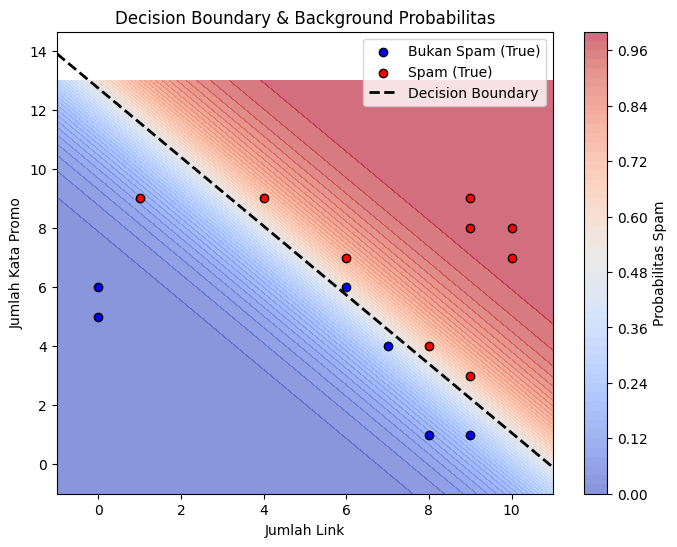

In [18]:
# Jawaban B4
plt.figure(figsize=(8, 6))
x_min, x_max = X_email[:, 0].min() - 1, X_email[:, 0].max() + 1
y_min, y_max = X_email[:, 1].min() - 1, X_email[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
grid_points = np.c_[xx.ravel(), yy.ravel()]
probs = log_reg.predict_proba(grid_points).reshape(xx.shape)

plt.contourf(xx, yy, probs, levels=50, cmap='coolwarm', alpha=0.6)
plt.colorbar(label='Probabilitas Spam')

plt.scatter(X_test_e[y_test_e == 0, 0], X_test_e[y_test_e == 0, 1], color='blue', label='Bukan Spam (True)', edgecolors='k')
plt.scatter(X_test_e[y_test_e == 1, 0], X_test_e[y_test_e == 1, 1], color='red', label='Spam (True)', edgecolors='k')

b_val = log_reg.b
m1, m2 = log_reg.weights
x1_line = np.linspace(x_min, x_max, 100)
x2_line = -(b_val + m1 * x1_line) / m2
plt.plot(x1_line, x2_line, color='black', linewidth=2, linestyle='--', label='Decision Boundary')

plt.title('Decision Boundary & Background Probabilitas')
plt.xlabel('Jumlah Link')
plt.ylabel('Jumlah Kata Promo')
plt.legend()
plt.show()

**Jawaban B4 (analisis):**

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [19]:
# Jawaban B5
thresholds = [0.3, 0.5, 0.7]
results = []

for th in thresholds:
    preds = log_reg.predict(X_test_e, threshold=th)
    cm_th = get_confusion_matrix(y_test_e, preds)
    tn_t, fp_t, fn_t, tp_t = cm_th[0, 0], cm_th[0, 1], cm_th[1, 0], cm_th[1, 1]
    acc_t = (tp_t + tn_t) / np.sum(cm_th)
    prec_t = tp_t / (tp_t + fp_t) if (tp_t + fp_t) > 0 else 0
    rec_t = tp_t / (tp_t + fn_t) if (tp_t + fn_t) > 0 else 0
    results.append({'Threshold': th, 'Accuracy': acc_t, 'Precision': prec_t, 'Recall': rec_t})

df_thresh = pd.DataFrame(results)
print(df_thresh)

   Threshold  Accuracy  Precision    Recall
0        0.3  0.800000   0.800000  0.888889
1        0.5  0.866667   0.888889  0.888889
2        0.7  0.733333   1.000000  0.555556


**Jawaban B5 (analisis):**

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [20]:
# Jawaban B6
email_baru = np.array([
    [1, 2],
    [5, 6],
    [9, 10],
    [2, 11]
])

chosen_threshold = 0.5
probs_baru = log_reg.predict_proba(email_baru)
preds_baru = log_reg.predict(email_baru, threshold=chosen_threshold)

df_pred_baru = pd.DataFrame({
    'Email': ['E1', 'E2', 'E3', 'E4'],
    'JumlahLink': email_baru[:, 0],
    'KataPromo': email_baru[:, 1],
    'ProbabilitasSpam': probs_baru,
    'PrediksiKelas': preds_baru
})
print(df_pred_baru)

  Email  JumlahLink  KataPromo  ProbabilitasSpam  PrediksiKelas
0    E1           1          2          0.000467              0
1    E2           5          6          0.327288              0
2    E3           9         10          0.998029              1
3    E4           2         11          0.617914              1


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:** Logistic Regression termasuk algoritma klasifikasi karena fungsi keluarannya dipetakan ke rentang diskrit (biasanya 0 atau 1) menggunakan fungsi sigmoid, meskipun proses dasarnya menggunakan regresi linier untuk menghitung nilai kombinasi linear sebelum dimasukkan ke fungsi aktivasi sigmoid.

**Jawaban C2:** Normal equation mencari solusi optimal secara langsung menggunakan invers matriks tanpa iterasi, sedangkan gradient descent memperbarui bobot secara berulang menggunakan turunan fungsi loss. Gradient descent lebih baik digunakan ketika ukuran dataset sangat besar karena komputasi matriks invers pada normal equation menjadi sangat mahal dan lambat.

**Jawaban C3:** Model harus dievaluasi pada data testing untuk menguji kemampuan generalisasinya terhadap data baru yang belum pernah dilihat sebelumnya. Overfitting adalah kondisi ketika model terlalu menghafal data training sehingga memiliki performa yang buruk pada data testing.

**Jawaban C4:** Linear Regression menggunakan MSE karena target keluarannya berupa angka kontinu (kesalahan dihitung sebagai selisih kuadrat jarak). Logistic Regression menggunakan log loss (cross-entropy) karena target keluarannya berupa probabilitas biner, di mana fungsi log loss memberikan penalti yang tepat terhadap kesalahan tebakan probabilitas.

**Jawaban C5:** Hasil angka bisa berbeda karena nilai random_state Anda ditentukan dari 2 digit terakhir NIM Anda (sehingga pembagian data training dan testing berbeda dengan mahasiswa lain), yang menghasilkan subset data pelatihan dan bobot inisialisasi yang berbeda.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [21]:
# Jawaban Bonus
from sklearn.linear_model import LinearRegression, LogisticRegression

sk_lin = LinearRegression()
sk_lin.fit(X_train_a, y_train_a)
print(f"Sklearn LinReg Intercept: {sk_lin.intercept_:.4f}, Coef: {sk_lin.coef_[0]:.4f}")

sk_log = LogisticRegression(penalty='l2', C=1.0, random_state=RANDOM_STATE)
sk_log.fit(X_train_e, y_train_e)
print(f"Sklearn LogReg Intercept: {sk_log.intercept_[0]:.4f}, Coef: {sk_log.coef_[0]}")

Sklearn LinReg Intercept: 28.8540, Coef: 9.0063
Sklearn LogReg Intercept: -9.4317, Coef: [0.85063677 0.74421299]


**Jawaban Bonus (analisis):** Koefisien antara implementasi manual dan scikit-learn mungkin memiliki sedikit perbedaan terutama pada Logistic Regression. Hal ini disebabkan scikit-learn secara default menggunakan regularisasi $L_2$ (Ridge) dengan parameter penalti tertentu (C=1.0), serta menggunakan solver optimasi tingkat lanjut (seperti L-BFGS) alih-alih murni standard gradient descent biasa.